# 🤖 Telco Customer Churn — Full Improved Model Building

**Dataset:** IBM Telco Customer Churn  
**Original Tutorial Inspiration:** [Channel Name — Link]  

**What's in this version:**
| Section | What's there |
|---|---|
| Data leakage fix | SMOTEENN on training data only |
| Stratified split | `stratify=y` preserves class ratio |
| 4 models compared | LR (baseline), DT, RF, Gradient Boosting |
| Confusion matrices | Heatmaps with count + % for all models |
| ROC curves | All models on one chart |
| Precision-Recall curves | More honest metric for imbalanced data |
| Feature importance | Random Forest top-25 features |
| 🆕 Learning curves | Diagnose overfitting vs underfitting |
| 🆕 Threshold tuning | Find optimal decision threshold per model |
| 🆕 Hyperparameter tuning | RandomizedSearchCV on best model |
| 🆕 Voting Classifier | Soft-voting ensemble of top 3 models |
| 🆕 SHAP values | Individual prediction explanations |
| 🆕 Calibration curves | Are predicted probabilities trustworthy? |
| Model comparison | Bar chart + radar chart across 5 metrics |
| Cross-validation | 5-fold stratified CV with box plots |
| Model saving | Model + scaler + features in one pickle |


## 1 · Imports & Style

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mtick
import seaborn as sns
import pickle
import warnings
warnings.filterwarnings('ignore')



In [4]:
from sklearn.model_selection  import (train_test_split, StratifiedKFold,
                                       cross_val_score, RandomizedSearchCV,
                                       learning_curve)
from sklearn.preprocessing    import StandardScaler
from sklearn.linear_model     import LogisticRegression
from sklearn.tree             import DecisionTreeClassifier
from sklearn.ensemble         import (RandomForestClassifier,
                                       GradientBoostingClassifier,
                                       VotingClassifier)
from sklearn.calibration      import calibration_curve, CalibratedClassifierCV
from sklearn.metrics          import (classification_report, confusion_matrix,
                                       roc_auc_score, roc_curve,
                                       precision_recall_curve, average_precision_score,
                                       f1_score, precision_score, recall_score)
from imblearn.combine         import SMOTEENN

try:
    import shap
    SHAP_AVAILABLE = True
    print("SHAP available ✔")
except ImportError:
    SHAP_AVAILABLE = False
    print("SHAP not installed — run: pip install shap")

# ── Colour palette ─────────────────────────────────────────────────────────────
CLR_NO  = '#4DA8DA'
CLR_YES = '#E8665A'
PALETTE = [CLR_NO, CLR_YES]
MODEL_COLORS = ['#2ecc71', '#e67e22', '#9b59b6', '#1abc9c', '#f39c12']

sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)
plt.rcParams.update({
    'figure.dpi'       : 120,
    'figure.facecolor' : 'white',
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.titlepad'    : 14,
})
print("Libraries loaded ✔")

SHAP not installed — run: pip install shap
Libraries loaded ✔


## 2 · Load Processed Data

In [5]:
df = pd.read_csv('telco_churn_processed.csv')
print(f"Shape : {df.shape}")
print(f"\nChurn balance:\n{df['Churn'].value_counts()}")
print(f"\nClass ratio: {df['Churn'].value_counts(normalize=True).round(3).to_dict()}")
df.head(3)

Shape : (7032, 51)

Churn balance:
Churn
0    5163
1    1869
Name: count, dtype: int64

Class ratio: {0: 0.734, 1: 0.266}


,SeniorCitizen,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_1–12 mo,tenure_group_13–24 mo,tenure_group_25–36 mo,tenure_group_37–48 mo,tenure_group_49–60 mo,tenure_group_61–72 mo
0,0,29.85,29.85,0,True,False,False,True,True,False,...,False,False,True,False,True,False,False,False,False,False
1,0,56.95,1889.50,0,False,True,True,False,True,False,...,False,False,False,True,False,False,True,False,False,False
2,0,53.85,108.15,1,False,True,True,False,True,False,...,False,False,False,True,True,False,False,False,False,False


## 3 · Feature & Target Split

In [6]:
X = df.drop(columns=['Churn'])
y = df['Churn']
print(f"Features : {X.shape[1]}")
print(f"Samples  : {X.shape[0]:,}")

Features : 50
Samples  : 7,032


## 4 · Stratified Train / Test Split

`stratify=y` ensures both splits maintain the 73:27 class ratio.  
Without this, the test set could accidentally be easier or harder than real-world data.


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train : {X_train.shape[0]:,} rows  |  Churn rate: {y_train.mean():.2%}")
print(f"Test  : {X_test.shape[0]:,} rows   |  Churn rate: {y_test.mean():.2%}")

Train : 5,625 rows  |  Churn rate: 26.58%
Test  : 1,407 rows   |  Churn rate: 26.58%


## 5 · Handle Class Imbalance — SMOTEENN (Training Only)

> ⚠️ **Common bug in tutorials:** applying SMOTEENN on the full dataset before splitting leaks test data into training, inflating all scores artificially.  
> **Correct:** split first → resample training data only → test set stays untouched.


In [8]:
sm = SMOTEENN(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

print(f"Before SMOTEENN → {dict(pd.Series(y_train).value_counts().sort_index())}")
print(f"After  SMOTEENN → {dict(pd.Series(y_train_res).value_counts().sort_index())}")
print(f"\nTraining samples: {len(y_train):,} → {len(y_train_res):,}")

Before SMOTEENN → {0: np.int64(4130), 1: np.int64(1495)}
After  SMOTEENN → {0: np.int64(2166), 1: np.int64(2499)}

Training samples: 5,625 → 4,665


## 6 · Feature Scaling

In [9]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_res)   # fit + transform (train only)
X_test_sc  = scaler.transform(X_test)             # transform only  (test)
print("Scaling complete ✔")

Scaling complete ✔


## 7 · Define Models

In [10]:
models = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree'       : DecisionTreeClassifier(criterion='gini', max_depth=6,
                                                    min_samples_leaf=8, random_state=42),
    'Random Forest'       : RandomForestClassifier(n_estimators=100, max_depth=6,
                                                    min_samples_leaf=8, random_state=42),
    'Gradient Boosting'   : GradientBoostingClassifier(n_estimators=100,
                                                        max_depth=4, random_state=42),
}
print("Models defined:", list(models.keys()))

Models defined: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


## 8 · Train & Collect Results

In [11]:
results = {}

for name, model in models.items():
    model.fit(X_train_sc, y_train_res)
    y_pred  = model.predict(X_test_sc)
    y_proba = model.predict_proba(X_test_sc)[:, 1]
    report  = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    auc     = roc_auc_score(y_test, y_proba)
    ap      = average_precision_score(y_test, y_proba)

    results[name] = {'model': model, 'y_pred': y_pred, 'y_proba': y_proba,
                     'report': report, 'auc': auc, 'ap': ap}

    print(f"✔  {name:<25} | Acc: {report['accuracy']:.3f}  "
          f"F1-churn: {report['1']['f1-score']:.3f}  AUC: {auc:.3f}")

✔  Logistic Regression       | Acc: 0.763  F1-churn: 0.610  AUC: 0.826
✔  Decision Tree             | Acc: 0.748  F1-churn: 0.599  AUC: 0.798
✔  Random Forest             | Acc: 0.734  F1-churn: 0.604  AUC: 0.830
✔  Gradient Boosting         | Acc: 0.763  F1-churn: 0.617  AUC: 0.830


## 9 · Classification Reports

In [12]:
for name, res in results.items():
    print(f"{'─'*55}")
    print(f"  {name}")
    print(f"{'─'*55}")
    print(classification_report(y_test, res['y_pred'],
                                target_names=['No Churn', 'Churn'], zero_division=0))

───────────────────────────────────────────────────────
  Logistic Regression
───────────────────────────────────────────────────────
              precision    recall  f1-score   support

    No Churn       0.88      0.79      0.83      1033
       Churn       0.54      0.70      0.61       374

    accuracy                           0.76      1407
   macro avg       0.71      0.74      0.72      1407
weighted avg       0.79      0.76      0.77      1407

───────────────────────────────────────────────────────
  Decision Tree
───────────────────────────────────────────────────────
              precision    recall  f1-score   support

    No Churn       0.88      0.76      0.82      1033
       Churn       0.52      0.71      0.60       374

    accuracy                           0.75      1407
   macro avg       0.70      0.74      0.71      1407
weighted avg       0.78      0.75      0.76      1407

───────────────────────────────────────────────────────
  Random Forest
────────────

**Why not just look at accuracy?**  
A model that predicts *everyone* as retained gets ~73% accuracy but catches 0% of churners.  
**Recall for the Churn class** is the most business-critical metric — we want to catch churners before they leave.


## 10 · Confusion Matrix Heatmaps

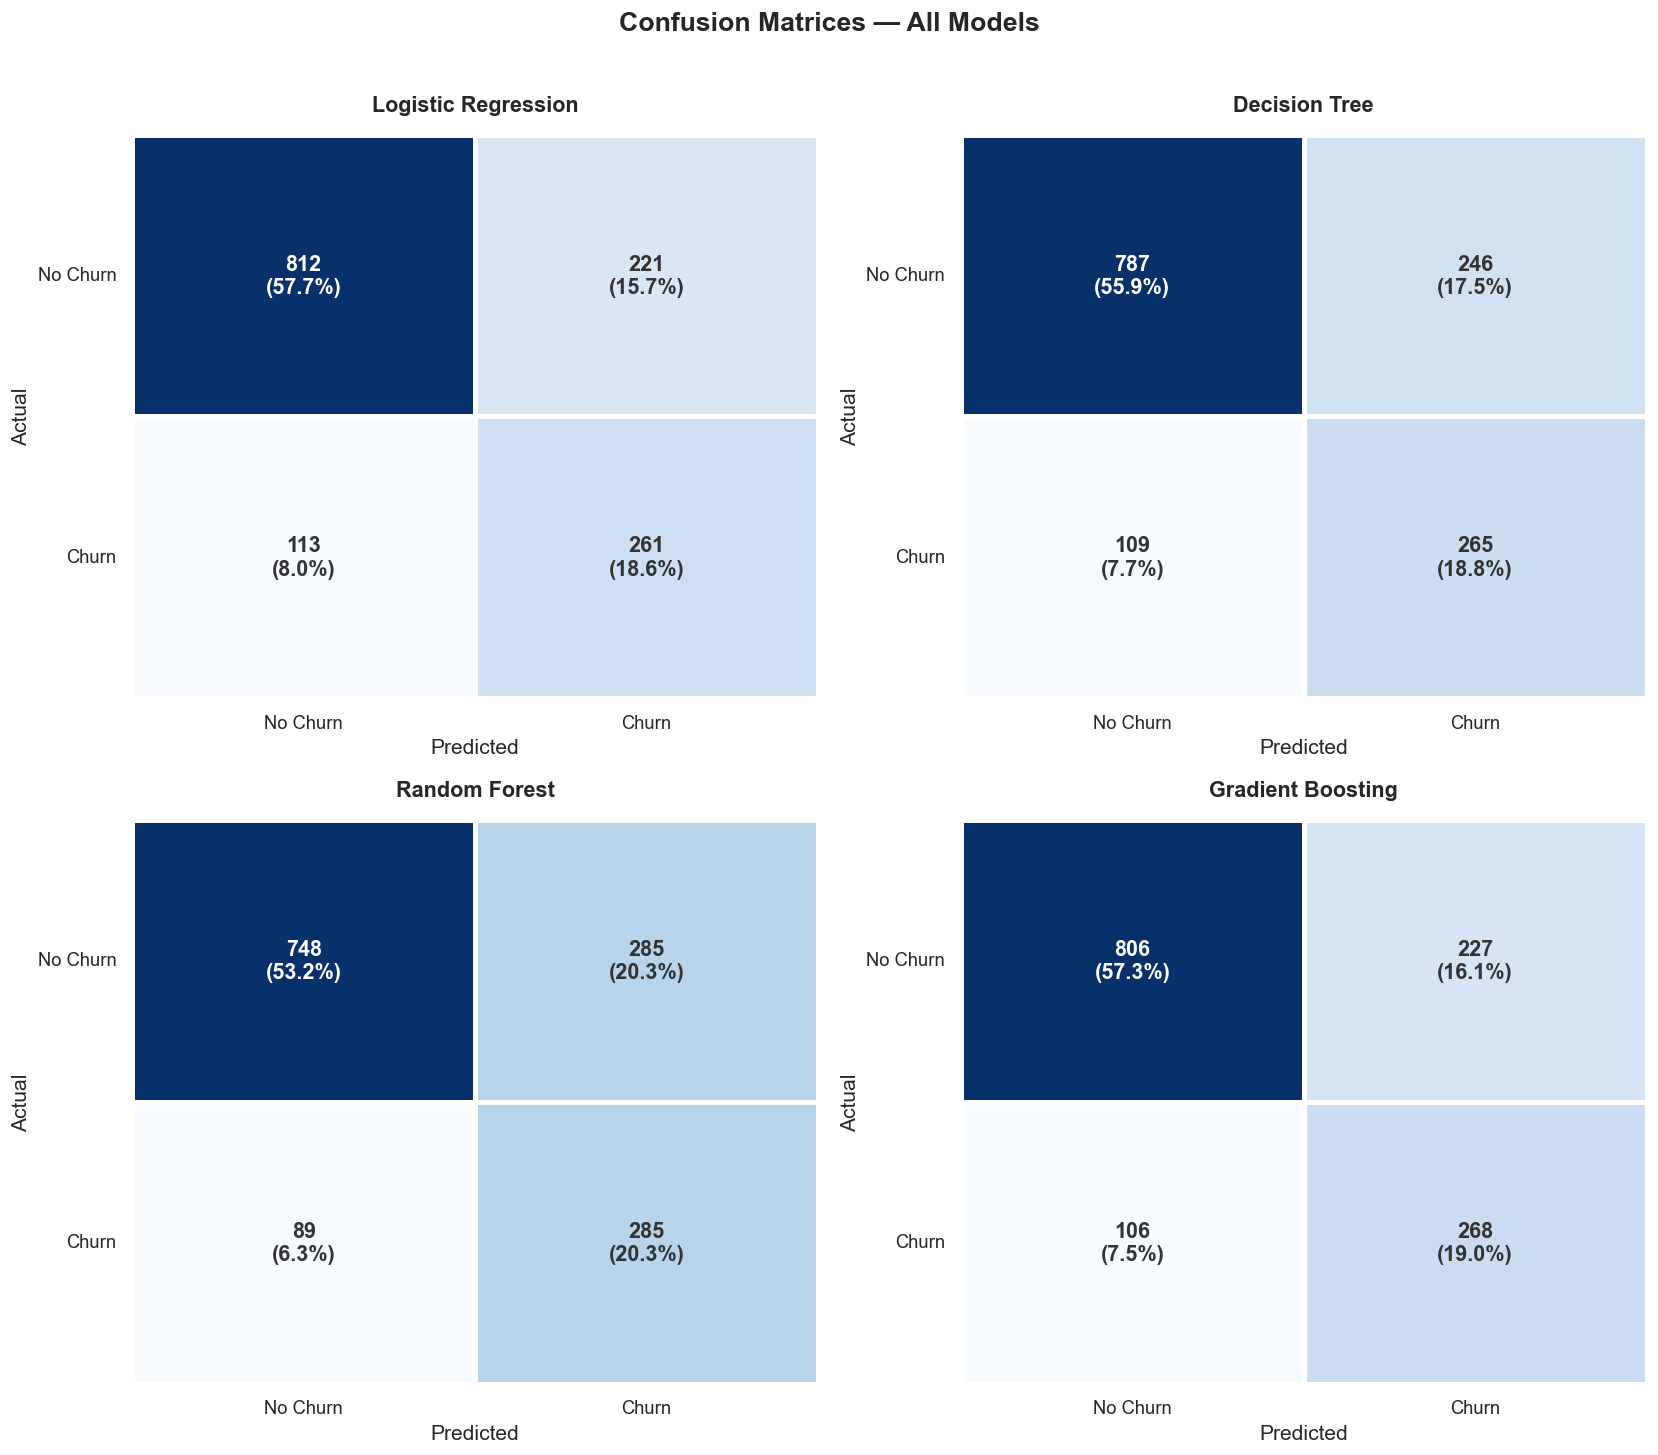

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Confusion Matrices — All Models', fontsize=16, fontweight='bold', y=1.01)

for ax, (name, res) in zip(axes.flatten(), results.items()):
    cm     = confusion_matrix(y_test, res['y_pred'])
    cm_pct = cm.astype(float) / cm.sum()

    sns.heatmap(cm, annot=False, cmap='Blues', ax=ax,
                linewidths=2, linecolor='white', cbar=False)

    for i in range(2):
        for j in range(2):
            ax.text(j+0.5, i+0.5,
                    f"{cm[i,j]:,}\n({100*cm_pct[i,j]:.1f}%)",
                    ha='center', va='center', fontsize=13, fontweight='bold',
                    color='white' if cm_pct[i,j] > 0.3 else '#333')

    ax.set_title(name, fontsize=13, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticklabels(['No Churn', 'Churn'], fontsize=11)
    ax.set_yticklabels(['No Churn', 'Churn'], fontsize=11, rotation=0)

plt.tight_layout()
plt.show()

## 11 · ROC Curves — All Models

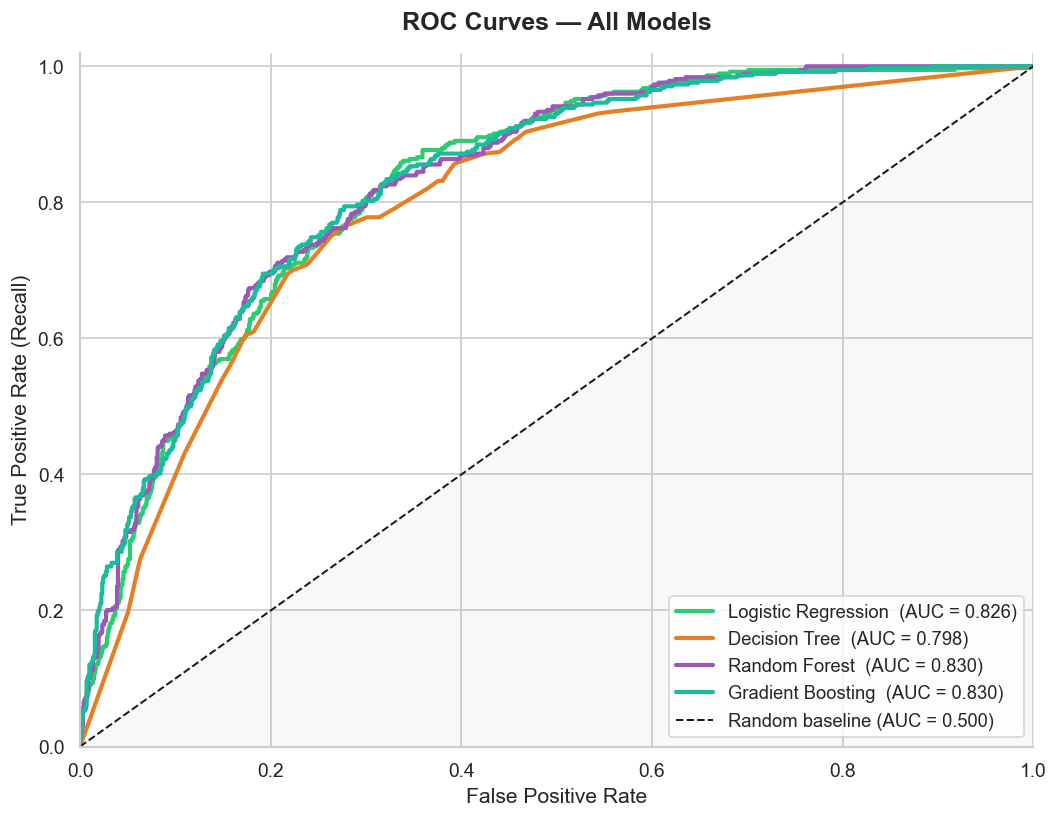

In [14]:
fig, ax = plt.subplots(figsize=(9, 7))

for (name, res), color in zip(results.items(), MODEL_COLORS):
    fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
    ax.plot(fpr, tpr, color=color, linewidth=2.5,
            label=f"{name}  (AUC = {res['auc']:.3f})")

ax.plot([0,1],[0,1], 'k--', linewidth=1.2, label='Random baseline (AUC = 0.500)')
ax.fill_between([0,1],[0,1], alpha=0.05, color='grey')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('ROC Curves — All Models', fontsize=15, fontweight='bold')
ax.legend(fontsize=11, loc='lower right')
ax.set_xlim(0,1); ax.set_ylim(0,1.02)
plt.tight_layout()
plt.show()

## 12 · Precision-Recall Curves

More informative than ROC on imbalanced datasets — directly shows the trade-off between catching churners (recall) and false alarm rate (precision).


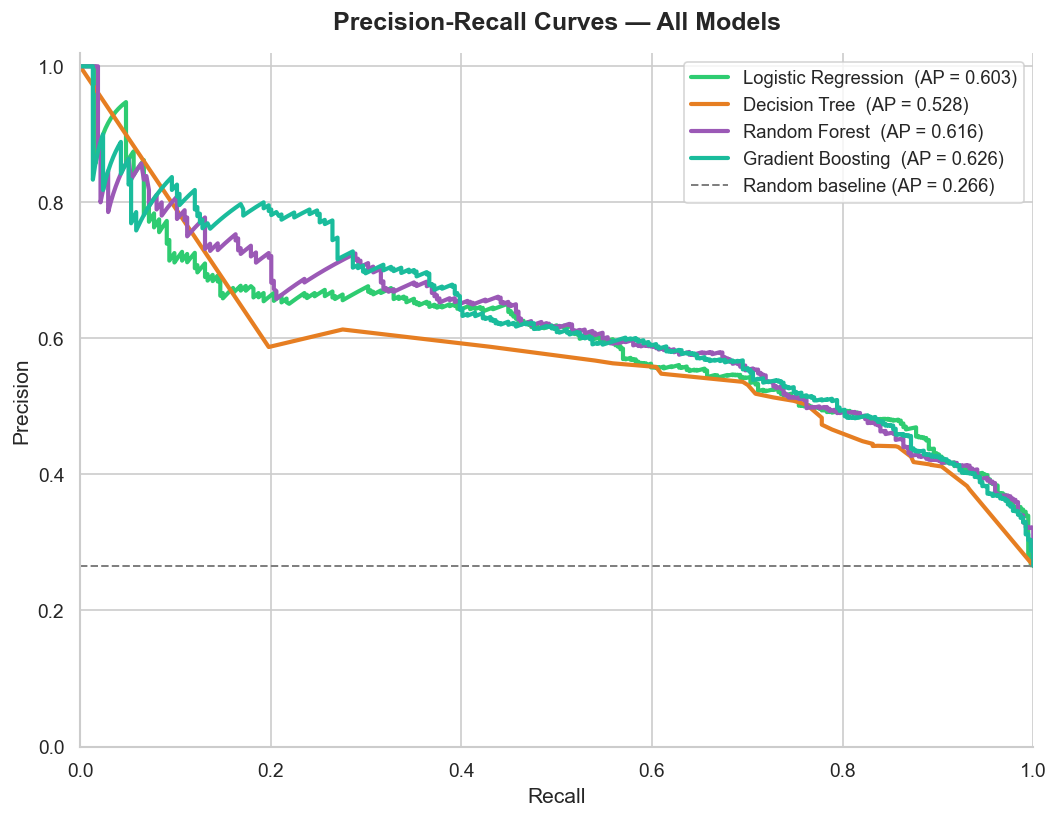

In [15]:
fig, ax = plt.subplots(figsize=(9, 7))

for (name, res), color in zip(results.items(), MODEL_COLORS):
    prec, rec, _ = precision_recall_curve(y_test, res['y_proba'])
    ax.plot(rec, prec, color=color, linewidth=2.5,
            label=f"{name}  (AP = {res['ap']:.3f})")

baseline = y_test.mean()
ax.axhline(baseline, color='grey', linestyle='--', linewidth=1.2,
           label=f'Random baseline (AP = {baseline:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves — All Models', fontsize=15, fontweight='bold')
ax.legend(fontsize=11)
ax.set_xlim(0,1); ax.set_ylim(0,1.02)
plt.tight_layout()
plt.show()

## 13 · Feature Importance — Random Forest

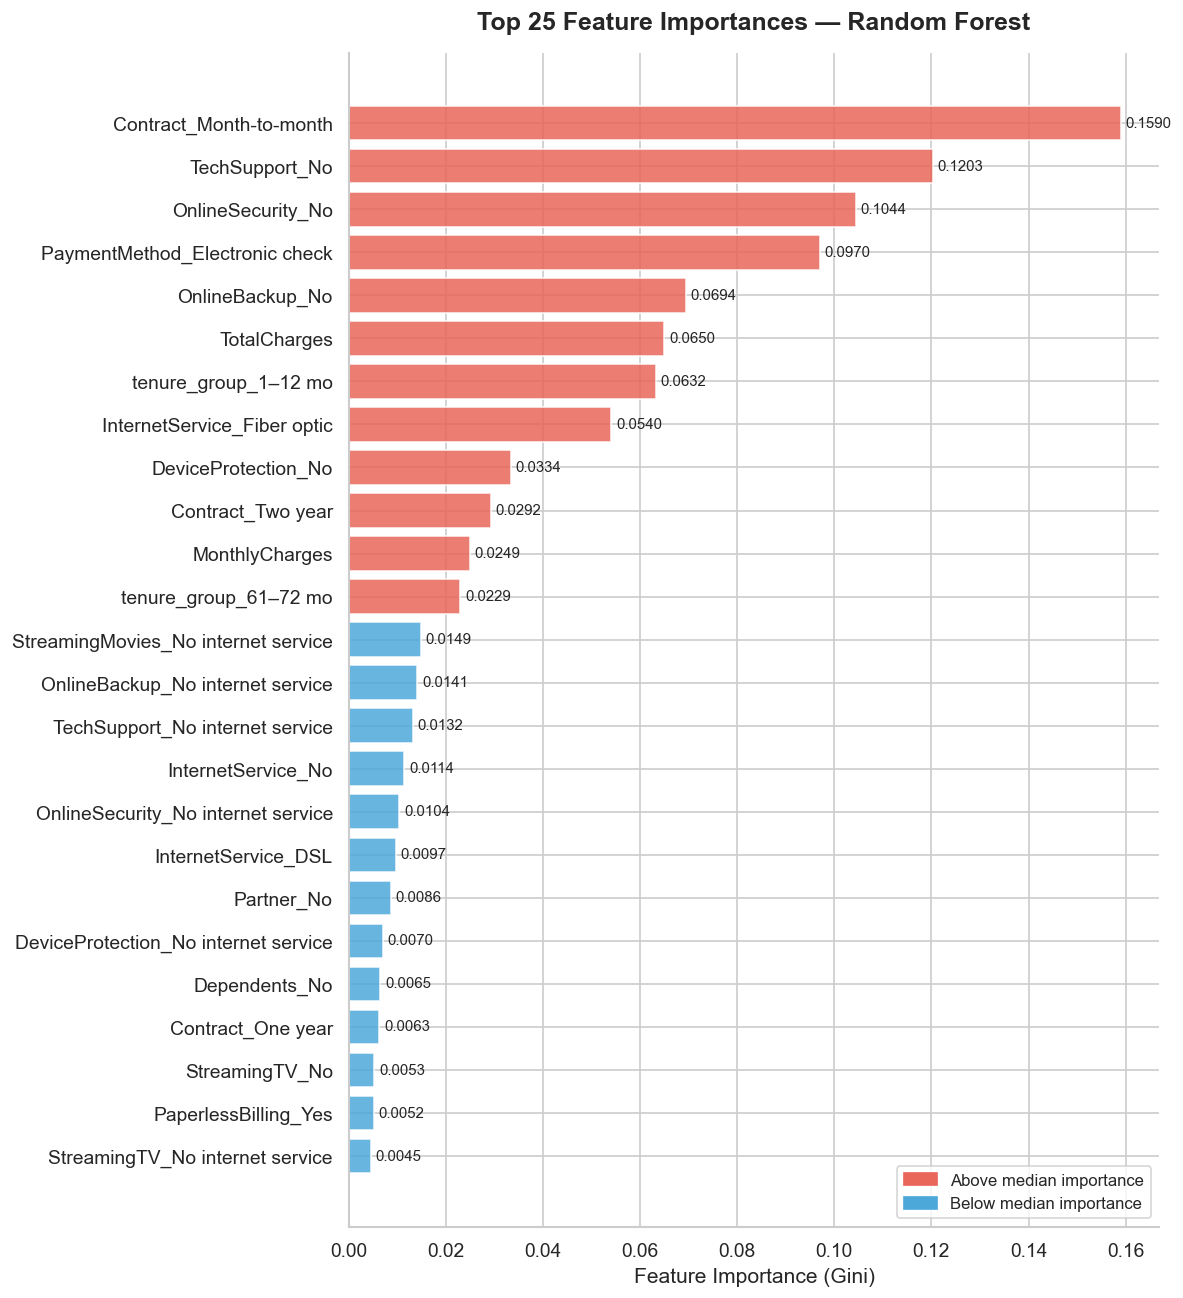

In [16]:
rf_model = results['Random Forest']['model']
feat_imp = (pd.DataFrame({
    'Feature'   : X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=True).tail(25))

fig, ax = plt.subplots(figsize=(10, 11))
colors = [CLR_YES if v > feat_imp['Importance'].median() else CLR_NO
          for v in feat_imp['Importance']]
bars = ax.barh(feat_imp['Feature'], feat_imp['Importance'],
               color=colors, alpha=0.85, edgecolor='white')

for bar, val in zip(bars, feat_imp['Importance']):
    ax.text(bar.get_width()+0.001, bar.get_y()+bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=9)

patches = [mpatches.Patch(color=CLR_YES, label='Above median importance'),
           mpatches.Patch(color=CLR_NO,  label='Below median importance')]
ax.legend(handles=patches, fontsize=10)
ax.set_xlabel('Feature Importance (Gini)')
ax.set_title('Top 25 Feature Importances — Random Forest', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 14 · Learning Curves

Learning curves reveal whether a model is **overfitting** (training score >> validation score) or **underfitting** (both scores low).  
They show how performance changes as we add more training data — a converging gap means the model generalises well.


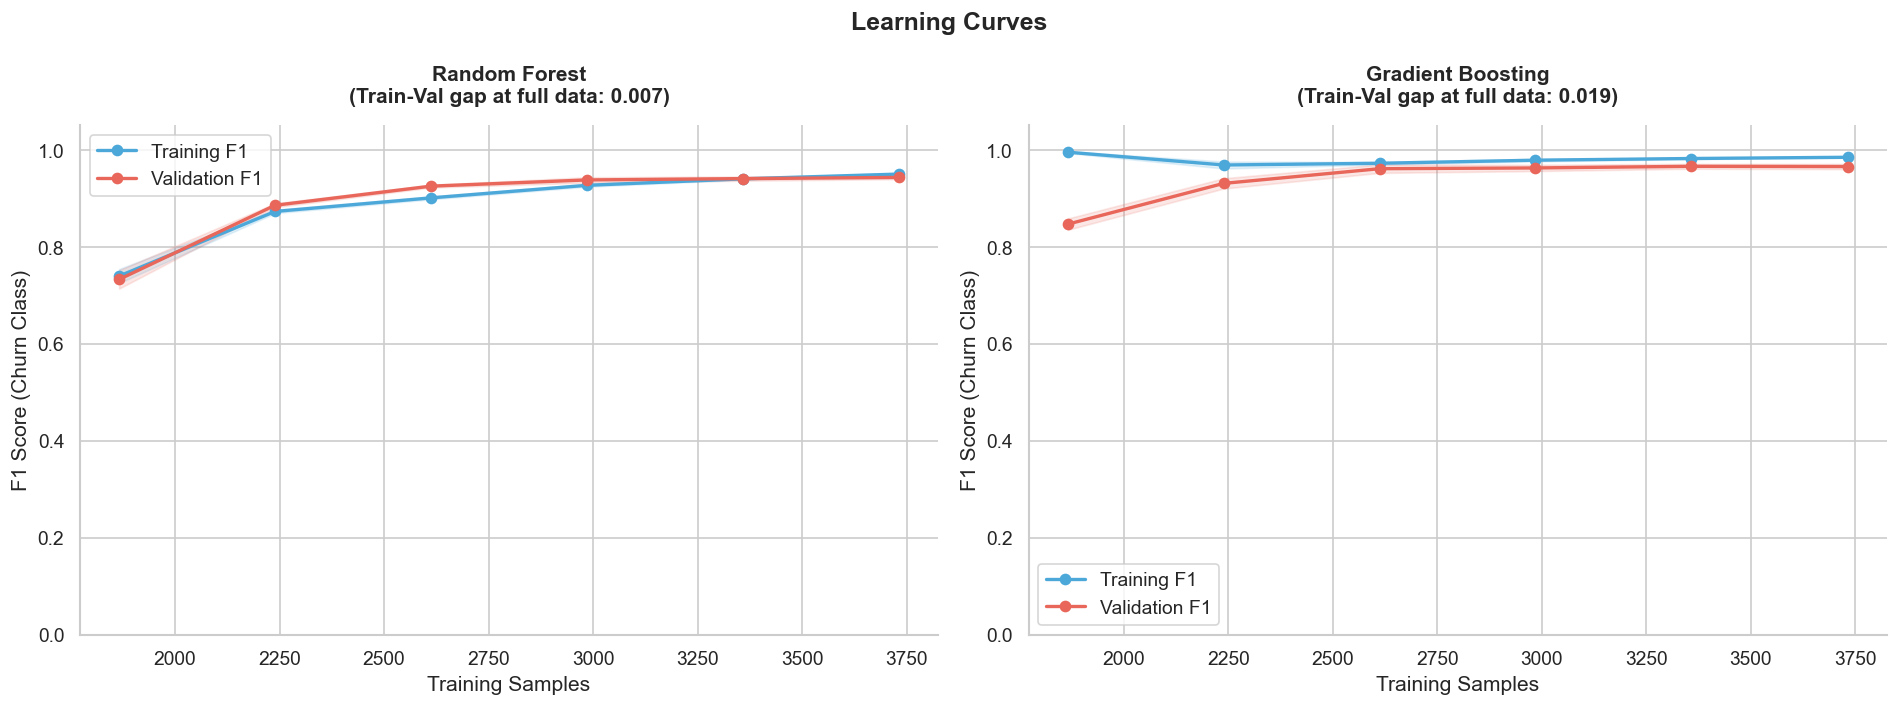

In [17]:
learn_models = {
    'Random Forest'    : results['Random Forest']['model'],
    'Gradient Boosting': results['Gradient Boosting']['model'],
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Learning Curves', fontsize=15, fontweight='bold')
cv_lc = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for ax, (name, model) in zip(axes, learn_models.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train_sc, y_train_res,
        cv=cv_lc, scoring='f1',
        train_sizes=np.linspace(0.10, 1.0, 10),
        n_jobs=-1
    )
    tr_mean = train_scores.mean(axis=1)
    tr_std  = train_scores.std(axis=1)
    vl_mean = val_scores.mean(axis=1)
    vl_std  = val_scores.std(axis=1)

    ax.plot(train_sizes, tr_mean, 'o-', color=CLR_NO,  linewidth=2, label='Training F1')
    ax.fill_between(train_sizes, tr_mean-tr_std, tr_mean+tr_std, alpha=0.15, color=CLR_NO)
    ax.plot(train_sizes, vl_mean, 'o-', color=CLR_YES, linewidth=2, label='Validation F1')
    ax.fill_between(train_sizes, vl_mean-vl_std, vl_mean+vl_std, alpha=0.15, color=CLR_YES)

    gap = tr_mean[-1] - vl_mean[-1]
    ax.set_title(f'{name}\n(Train-Val gap at full data: {gap:.3f})', fontweight='bold')
    ax.set_xlabel('Training Samples')
    ax.set_ylabel('F1 Score (Churn Class)')
    ax.legend()
    ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

**How to read this:**  
- **Large gap** between train and val → overfitting (model memorises training data)  
- **Both curves low** → underfitting (model too simple)  
- **Curves converging** → good generalisation  
- **Val curve still rising** at the end → more data would help  


## 15 · Decision Threshold Tuning

By default, classifiers predict class 1 (Churn) when probability ≥ 0.5.  
But **0.5 is rarely the optimal threshold** — especially on imbalanced data.  

Lowering the threshold catches more churners (higher recall) but also flags more non-churners (lower precision). The best threshold depends on the business cost of each error type.


In [18]:
thresholds  = np.linspace(0.01, 0.99, 200)
best_name   = max(results, key=lambda n: results[n]['report']['1']['f1-score'])
best_proba  = results[best_name]['y_proba']

f1_scores   = []
prec_scores = []
rec_scores  = []

for t in thresholds:
    y_t = (best_proba >= t).astype(int)
    f1_scores.append(f1_score(y_test, y_t, zero_division=0))
    prec_scores.append(precision_score(y_test, y_t, zero_division=0))
    rec_scores.append(recall_score(y_test, y_t, zero_division=0))

optimal_thresh = thresholds[np.argmax(f1_scores)]
print(f"Best model for threshold analysis : {best_name}")
print(f"Default threshold (0.50) F1       : {f1_scores[np.argmin(np.abs(thresholds-0.5))]:.4f}")
print(f"Optimal threshold                  : {optimal_thresh:.3f}")
print(f"Optimal threshold F1               : {max(f1_scores):.4f}")

Best model for threshold analysis : Gradient Boosting
Default threshold (0.50) F1       : 0.6161
Optimal threshold                  : 0.606
Optimal threshold F1               : 0.6250


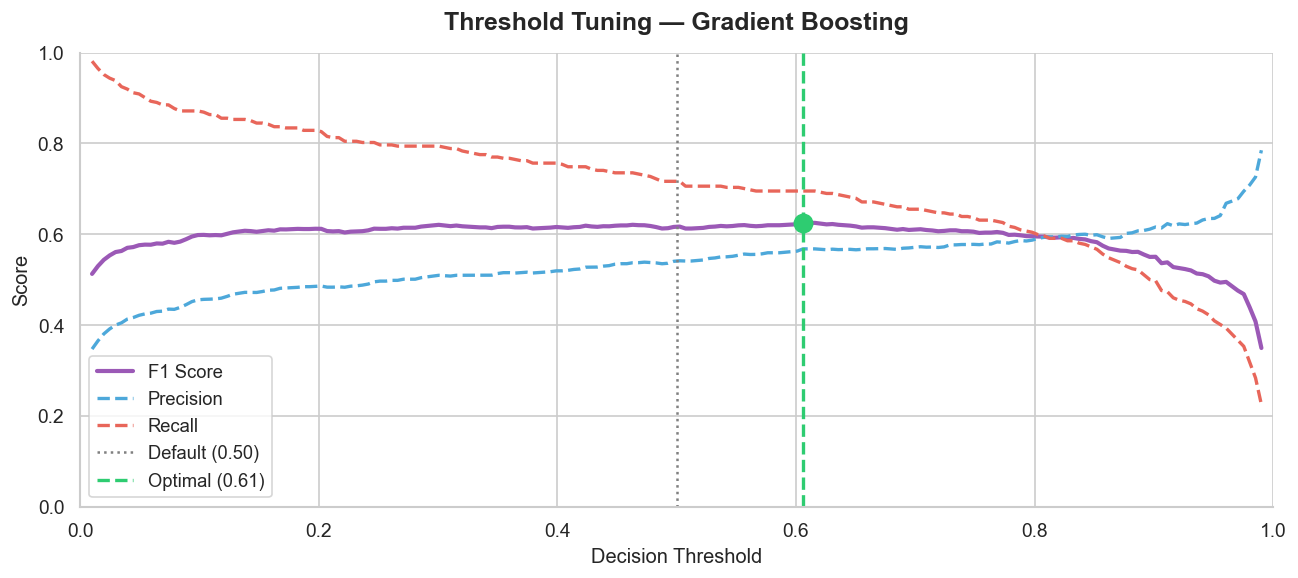

In [19]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(thresholds, f1_scores,   color='#9b59b6', linewidth=2.5, label='F1 Score')
ax.plot(thresholds, prec_scores, color=CLR_NO,    linewidth=2,   label='Precision', linestyle='--')
ax.plot(thresholds, rec_scores,  color=CLR_YES,   linewidth=2,   label='Recall',    linestyle='--')
ax.axvline(0.50,            color='grey',    linestyle=':',  linewidth=1.5, label='Default (0.50)')
ax.axvline(optimal_thresh,  color='#2ecc71', linestyle='--', linewidth=2,   label=f'Optimal ({optimal_thresh:.2f})')
ax.scatter([optimal_thresh], [max(f1_scores)], color='#2ecc71', s=120, zorder=5)

ax.set_xlabel('Decision Threshold', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title(f'Threshold Tuning — {best_name}', fontsize=15, fontweight='bold')
ax.legend(fontsize=11)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [20]:
# Apply optimal threshold and compare
y_pred_default = (best_proba >= 0.50).astype(int)
y_pred_optimal = (best_proba >= optimal_thresh).astype(int)

print(f"{'Metric':<25} {'Default (0.50)':>15}  {'Optimal ({:.2f})'.format(optimal_thresh):>15}")
print('─' * 58)
for metric, fn in [('Precision (Churn)', precision_score),
                   ('Recall (Churn)',    recall_score),
                   ('F1 (Churn)',        f1_score)]:
    d = fn(y_test, y_pred_default, zero_division=0)
    o = fn(y_test, y_pred_optimal, zero_division=0)
    diff = o - d
    print(f"{metric:<25} {d:>15.4f}  {o:>15.4f}  ({'+' if diff>=0 else ''}{diff:.4f})")

Metric                     Default (0.50)   Optimal (0.61)
──────────────────────────────────────────────────────────
Precision (Churn)                  0.5414           0.5677  (+0.0263)
Recall (Churn)                     0.7166           0.6952  (-0.0214)
F1 (Churn)                         0.6168           0.6250  (+0.0082)


## 16 · Hyperparameter Tuning — RandomizedSearchCV

Default parameters are rarely optimal. `RandomizedSearchCV` samples from a parameter distribution and uses cross-validation to find the best combination — faster than `GridSearchCV` with most of the benefit.


In [21]:
param_dist = {
    'n_estimators'   : [50, 100, 150, 200, 300],
    'max_depth'      : [3, 4, 5, 6, 8, None],
    'min_samples_leaf': [4, 8, 12, 16],
    'max_features'   : ['sqrt', 'log2', 0.5],
    'min_samples_split': [2, 5, 10],
}

cv_tune = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rs = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions = param_dist,
    n_iter      = 30,
    cv          = cv_tune,
    scoring     = 'f1',
    random_state= 42,
    n_jobs      = -1,
    verbose     = 0
)
rs.fit(X_train_sc, y_train_res)

print(f"Best params  : {rs.best_params_}")
print(f"Best CV F1   : {rs.best_score_:.4f}")

Best params  : {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': None}
Best CV F1   : 0.9572


In [22]:
# Evaluate tuned model
tuned_rf = rs.best_estimator_
y_pred_tuned  = tuned_rf.predict(X_test_sc)
y_proba_tuned = tuned_rf.predict_proba(X_test_sc)[:, 1]
auc_tuned     = roc_auc_score(y_test, y_proba_tuned)

print("=== Tuned Random Forest vs Default Random Forest ===")
print(f"{'Metric':<25} {'Default':>10}  {'Tuned':>10}  {'Change':>10}")
print('─' * 60)
base = results['Random Forest']
for metric, fn in [('F1 (Churn)', f1_score), ('Recall', recall_score), ('Precision', precision_score)]:
    d = fn(y_test, base['y_pred'], zero_division=0)
    t = fn(y_test, y_pred_tuned, zero_division=0)
    print(f"{metric:<25} {d:>10.4f}  {t:>10.4f}  {t-d:>+10.4f}")
print(f"{'ROC-AUC':<25} {base['auc']:>10.4f}  {auc_tuned:>10.4f}  {auc_tuned-base['auc']:>+10.4f}")

=== Tuned Random Forest vs Default Random Forest ===
Metric                       Default       Tuned      Change
────────────────────────────────────────────────────────────
F1 (Churn)                    0.6038      0.6229     +0.0191
Recall                        0.7620      0.7353     -0.0267
Precision                     0.5000      0.5403     +0.0403
ROC-AUC                       0.8298      0.8293     -0.0005


In [23]:
# Add tuned RF to results dict for ensemble
results['Tuned Random Forest'] = {
    'model': tuned_rf, 'y_pred': y_pred_tuned, 'y_proba': y_proba_tuned,
    'report': classification_report(y_test, y_pred_tuned, output_dict=True, zero_division=0),
    'auc': auc_tuned,
    'ap' : average_precision_score(y_test, y_proba_tuned)
}

## 17 · Ensemble — Soft Voting Classifier

Combines predictions from multiple models by averaging their predicted probabilities.  
Ensembles often outperform individual models because they reduce variance — when one model is wrong, others compensate.


In [24]:
voting_clf = VotingClassifier(
    estimators=[
        ('tuned_rf', tuned_rf),
        ('gb',       results['Gradient Boosting']['model']),
        ('lr',       results['Logistic Regression']['model']),
    ],
    voting='soft',
    n_jobs=-1
)
voting_clf.fit(X_train_sc, y_train_res)

y_pred_vc  = voting_clf.predict(X_test_sc)
y_proba_vc = voting_clf.predict_proba(X_test_sc)[:, 1]
auc_vc     = roc_auc_score(y_test, y_proba_vc)

results['Voting Ensemble'] = {
    'model': voting_clf, 'y_pred': y_pred_vc, 'y_proba': y_proba_vc,
    'report': classification_report(y_test, y_pred_vc, output_dict=True, zero_division=0),
    'auc': auc_vc,
    'ap' : average_precision_score(y_test, y_proba_vc)
}

print("=== Voting Ensemble Results ===")
print(classification_report(y_test, y_pred_vc, target_names=['No Churn', 'Churn'], zero_division=0))
print(f"ROC-AUC: {auc_vc:.4f}")

=== Voting Ensemble Results ===
              precision    recall  f1-score   support

    No Churn       0.89      0.78      0.83      1033
       Churn       0.54      0.72      0.62       374

    accuracy                           0.76      1407
   macro avg       0.71      0.75      0.72      1407
weighted avg       0.79      0.76      0.77      1407

ROC-AUC: 0.8338


## 18 · SHAP Values — Model Explainability

SHAP (SHapley Additive exPlanations) shows **which features pushed each individual prediction** toward churn or away from it.  
This is the gold standard for ML explainability and is heavily used in industry.

- **Summary bar plot** — average impact of each feature across all predictions  
- **Beeswarm plot** — each dot is one customer; colour = feature value; x position = impact on prediction  


In [25]:
if SHAP_AVAILABLE:
    explainer   = shap.TreeExplainer(tuned_rf)
    shap_values = explainer.shap_values(X_test_sc)

    # SHAP values for class 1 (Churn)
    shap_churn = shap_values[1] if isinstance(shap_values, list) else shap_values

    # ── Summary bar plot ────────────────────────────────────────────────────────
    plt.figure(figsize=(10, 10))
    shap.summary_plot(shap_churn, X_test_sc,
                      feature_names=X_train.columns.tolist(),
                      plot_type='bar', show=False, max_display=20)
    plt.title('SHAP Feature Importance (Mean |SHAP value|)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # ── Beeswarm plot ───────────────────────────────────────────────────────────
    plt.figure(figsize=(10, 10))
    shap.summary_plot(shap_churn, X_test_sc,
                      feature_names=X_train.columns.tolist(),
                      show=False, max_display=20)
    plt.title('SHAP Beeswarm — Feature Impact on Churn Prediction',
              fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("Install SHAP to see these plots: pip install shap")

Install SHAP to see these plots: pip install shap


In [26]:
if SHAP_AVAILABLE:
    # ── Waterfall plot for a single churned customer ────────────────────────────
    # Find a customer the model predicted as high churn risk
    high_churn_idx = np.argmax(y_proba_tuned)

    plt.figure(figsize=(10, 7))
    shap.waterfall_plot(
        shap.Explanation(
            values      = shap_churn[high_churn_idx],
            base_values = explainer.expected_value[1] if isinstance(explainer.expected_value, list)
                          else explainer.expected_value,
            data        = X_test_sc[high_churn_idx],
            feature_names = X_train.columns.tolist()
        ),
        show=False, max_display=15
    )
    plt.title(f'SHAP Waterfall — Why Did Customer #{high_churn_idx} Churn?',
              fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

## 19 · Calibration Curves

A model might say "70% probability of churn" — but does that actually mean 70% of those customers churn?  
**Calibration curves** check if predicted probabilities are reliable.  

A perfectly calibrated model follows the diagonal. Points above = model underestimates risk. Points below = overestimates.


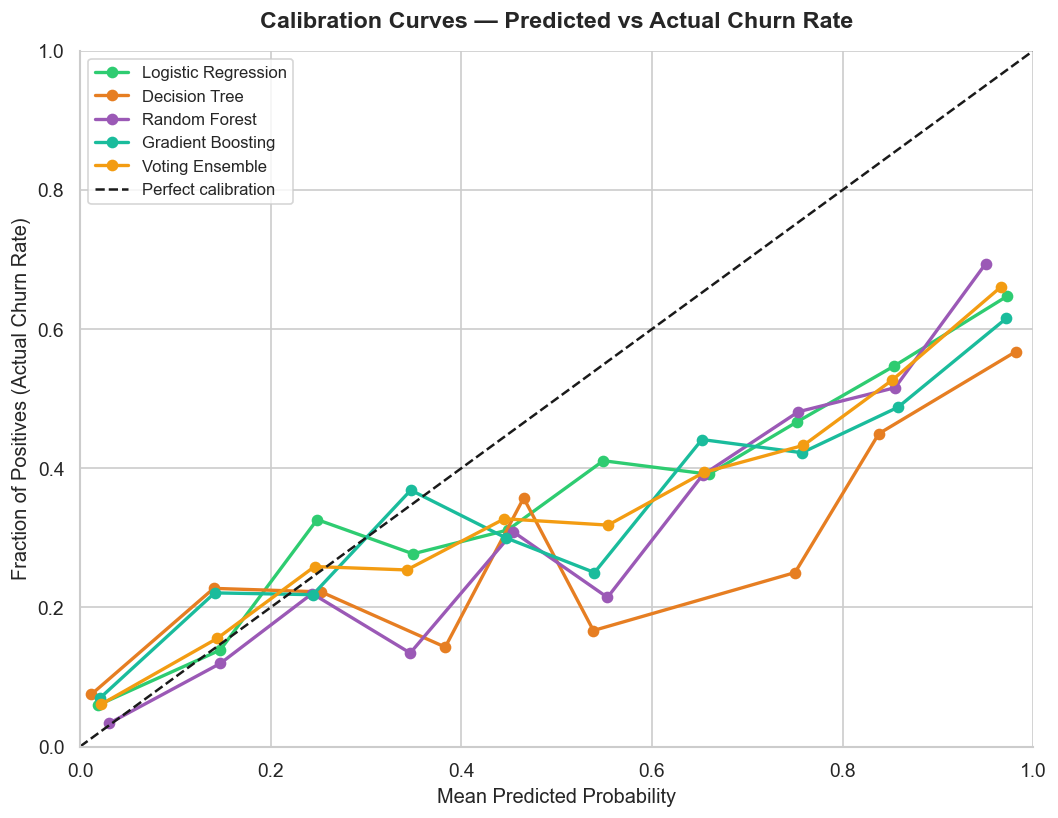

In [27]:
# Use base 4 models + ensemble
calib_models = {k: v for k, v in results.items()
                if k in ['Logistic Regression', 'Decision Tree',
                         'Random Forest', 'Gradient Boosting', 'Voting Ensemble']}

fig, ax = plt.subplots(figsize=(9, 7))

for (name, res), color in zip(calib_models.items(), MODEL_COLORS):
    fraction_pos, mean_pred = calibration_curve(y_test, res['y_proba'], n_bins=10)
    ax.plot(mean_pred, fraction_pos, marker='o', linewidth=2,
            color=color, label=name)

ax.plot([0,1],[0,1], 'k--', linewidth=1.5, label='Perfect calibration')
ax.set_xlabel('Mean Predicted Probability', fontsize=12)
ax.set_ylabel('Fraction of Positives (Actual Churn Rate)', fontsize=12)
ax.set_title('Calibration Curves — Predicted vs Actual Churn Rate',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.set_xlim(0,1); ax.set_ylim(0,1)
plt.tight_layout()
plt.show()

## 20 · 5-Fold Stratified Cross-Validation

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_models = {k: v['model'] for k, v in results.items()
             if k in ['Logistic Regression','Decision Tree',
                      'Random Forest','Gradient Boosting',
                      'Tuned Random Forest', 'Voting Ensemble']}

print(f"{'Model':<25} | {'CV F1 mean':>12}  {'CV F1 std':>10}  {'CV AUC mean':>12}")
print('─' * 68)
cv_results = {}
for name, model in cv_models.items():
    f1  = cross_val_score(model, X_test_sc, y_test, cv=cv, scoring='f1',      n_jobs=-1)
    auc = cross_val_score(model, X_test_sc, y_test, cv=cv, scoring='roc_auc', n_jobs=-1)
    cv_results[name] = {'f1': f1, 'auc': auc}
    print(f"{name:<25} | {f1.mean():>12.3f}  {f1.std():>10.3f}  {auc.mean():>12.3f}")

Model                     |   CV F1 mean   CV F1 std   CV AUC mean
────────────────────────────────────────────────────────────────────
Logistic Regression       |        0.534       0.039         0.820
Decision Tree             |        0.542       0.055         0.766
Random Forest             |        0.505       0.040         0.826
Gradient Boosting         |        0.514       0.045         0.809
Tuned Random Forest       |        0.528       0.040         0.819
Voting Ensemble           |        0.540       0.017         0.825


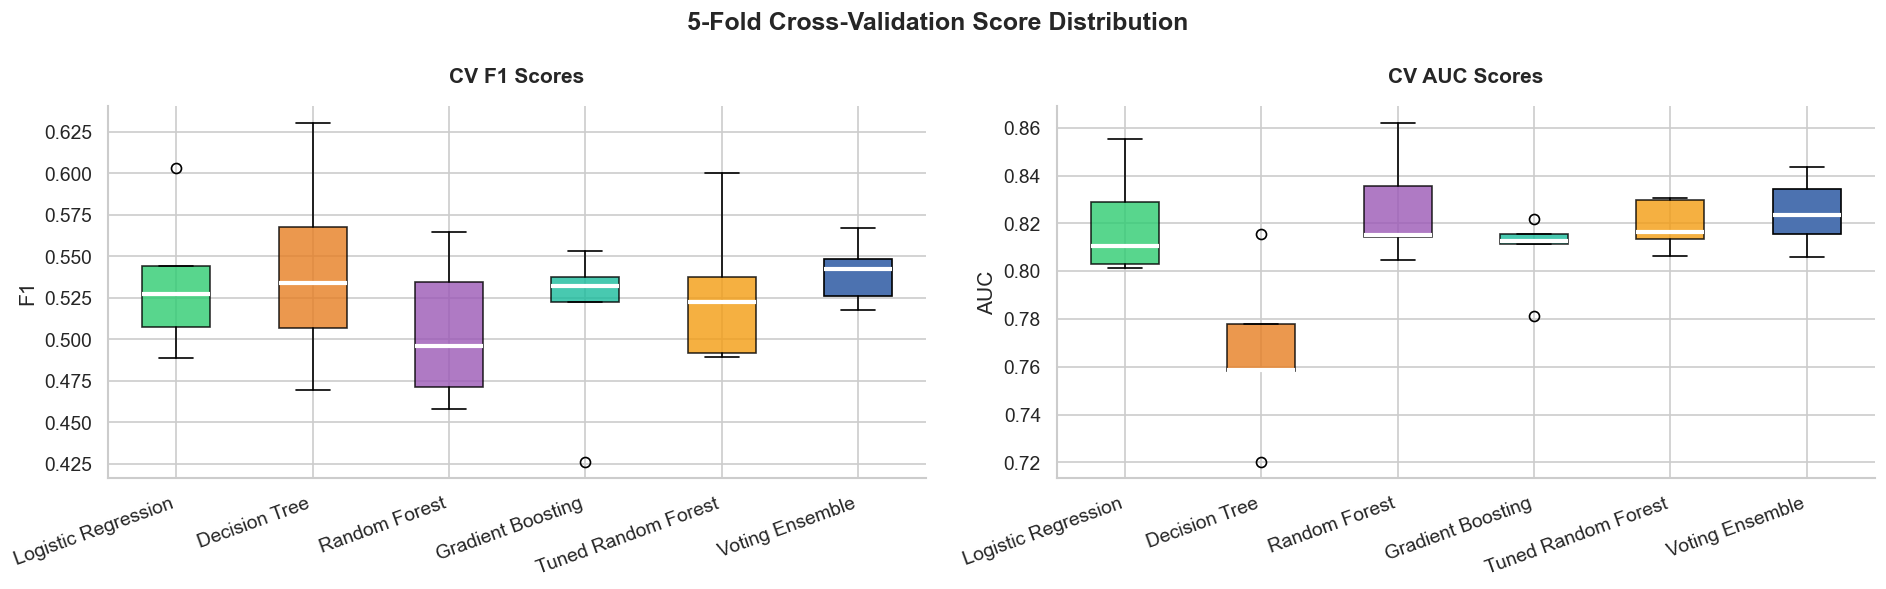

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('5-Fold Cross-Validation Score Distribution', fontsize=15, fontweight='bold')

for ax, metric in zip(axes, ['f1', 'auc']):
    data   = [cv_results[n][metric] for n in cv_results]
    labels = list(cv_results.keys())
    bp = ax.boxplot(data, patch_artist=True, widths=0.5,
                    medianprops=dict(color='white', linewidth=2.5))
    for patch, color in zip(bp['boxes'], MODEL_COLORS):
        patch.set_facecolor(color); patch.set_alpha(0.8)
    ax.set_xticks(range(1, len(labels)+1))
    ax.set_xticklabels(labels, rotation=20, ha='right')
    ax.set_title(f'CV {metric.upper()} Scores', fontweight='bold')
    ax.set_ylabel(metric.upper())

plt.tight_layout()
plt.show()

## 21 · Full Model Comparison Dashboard

In [30]:
# Summary table across all models
rows = []
for name, res in results.items():
    r = res['report']
    rows.append({
        'Model'            : name,
        'Accuracy'         : round(r['accuracy'], 3),
        'Precision (Churn)': round(r['1']['precision'], 3),
        'Recall (Churn)'   : round(r['1']['recall'], 3),
        'F1 (Churn)'       : round(r['1']['f1-score'], 3),
        'ROC-AUC'          : round(res['auc'], 3),
    })

summary_df = pd.DataFrame(rows).set_index('Model')
print("=== Full Summary Table ===")
print(summary_df.to_string())

=== Full Summary Table ===
                     Accuracy  Precision (Churn)  Recall (Churn)  F1 (Churn)  ROC-AUC
Model                                                                                
Logistic Regression     0.763              0.541           0.698       0.610    0.826
Decision Tree           0.748              0.519           0.709       0.599    0.798
Random Forest           0.734              0.500           0.762       0.604    0.830
Gradient Boosting       0.763              0.541           0.717       0.617    0.830
Tuned Random Forest     0.763              0.540           0.735       0.623    0.829
Voting Ensemble         0.763              0.540           0.722       0.618    0.834


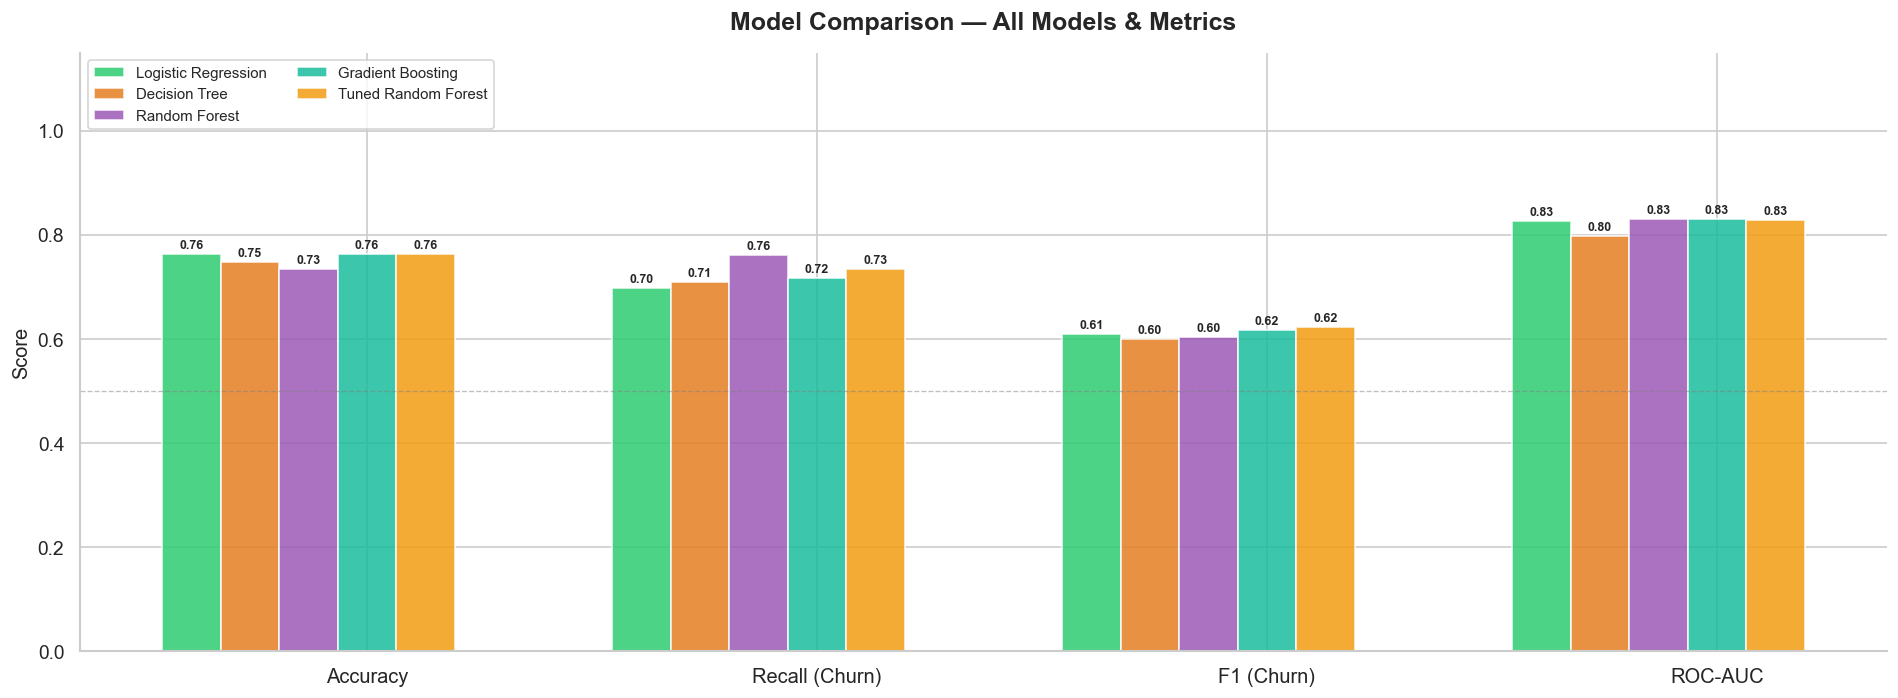

In [31]:
# Grouped bar comparison
metrics_to_plot = ['Accuracy', 'Recall (Churn)', 'F1 (Churn)', 'ROC-AUC']
plot_data = summary_df[metrics_to_plot]

x = np.arange(len(metrics_to_plot))
w = 0.13
fig, ax = plt.subplots(figsize=(16, 6))

for i, (model_name, color) in enumerate(zip(plot_data.index, MODEL_COLORS)):
    vals = plot_data.loc[model_name].values
    bars = ax.bar(x + i*w, vals, width=w, color=color, alpha=0.85,
                  edgecolor='white', label=model_name)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                f'{val:.2f}', ha='center', va='bottom', fontsize=7.5, fontweight='bold')

ax.set_xticks(x + w*(len(plot_data)//2))
ax.set_xticklabels(metrics_to_plot, fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_ylim(0, 1.15)
ax.set_title('Model Comparison — All Models & Metrics', fontsize=15, fontweight='bold')
ax.legend(fontsize=9, loc='upper left', ncol=2)
ax.axhline(0.5, color='grey', linestyle='--', linewidth=0.8, alpha=0.5)
plt.tight_layout()
plt.show()

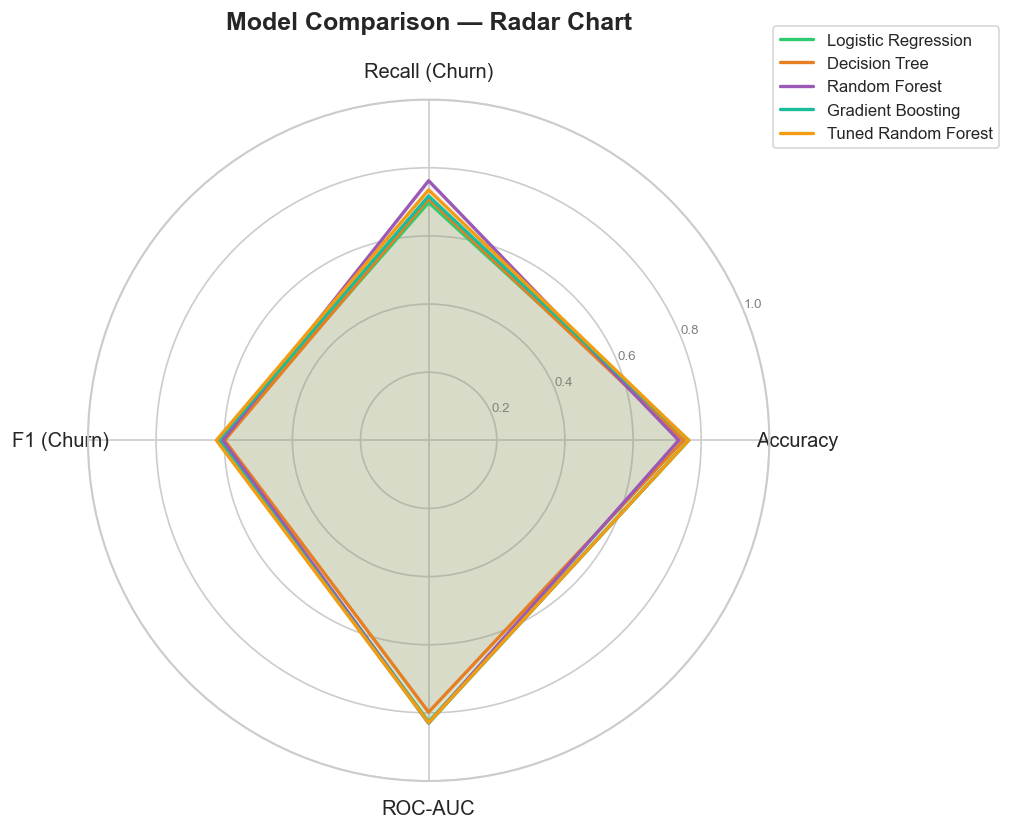

In [32]:
# Radar chart
categories = metrics_to_plot
N = len(categories)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))

for (model_name, color) in zip(plot_data.index, MODEL_COLORS):
    values = plot_data.loc[model_name].tolist() + [plot_data.loc[model_name].tolist()[0]]
    ax.plot(angles, values, color=color, linewidth=2, label=model_name)
    ax.fill(angles, values, color=color, alpha=0.08)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12)
ax.set_ylim(0,1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2','0.4','0.6','0.8','1.0'], fontsize=8, color='grey')
ax.set_title('Model Comparison — Radar Chart', fontsize=15, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.12), fontsize=10)
plt.tight_layout()
plt.show()

## 22 · Select Best Model & Save

Picking winner by **F1 score on the Churn class** — the most balanced single metric for this business problem.


In [33]:
best_name  = summary_df['F1 (Churn)'].idxmax()
best_model = results[best_name]['model']

print(f"Best model : {best_name}")
print(f"  F1 (Churn) : {summary_df.loc[best_name, 'F1 (Churn)']:.3f}")
print(f"  Recall     : {summary_df.loc[best_name, 'Recall (Churn)']:.3f}")
print(f"  ROC-AUC    : {summary_df.loc[best_name, 'ROC-AUC']:.3f}")

Best model : Tuned Random Forest
  F1 (Churn) : 0.623
  Recall     : 0.735
  ROC-AUC    : 0.829


In [34]:
payload = {
    'model'           : best_model,
    'scaler'          : scaler,
    'features'        : list(X.columns),
    'best_model_name' : best_name,
    'optimal_threshold': optimal_thresh,   # from threshold tuning
    'summary_metrics' : summary_df.to_dict(),
}

with open('churn_model.pkl', 'wb') as f:
    pickle.dump(payload, f)

print(f"Saved → churn_model.pkl")
print(f"Includes: model, scaler, feature list, optimal threshold ({optimal_thresh:.3f}), metrics summary")

Saved → churn_model.pkl
Includes: model, scaler, feature list, optimal threshold (0.606), metrics summary


In [35]:
# Verify reload
with open('churn_model.pkl', 'rb') as f:
    loaded = pickle.load(f)

sample = loaded['scaler'].transform(X_test.iloc[:5])
preds  = (loaded['model'].predict_proba(sample)[:, 1] >= loaded['optimal_threshold']).astype(int)
print(f"Sample predictions (with optimal threshold): {preds}")
print("Model reload verified ✔")

Sample predictions (with optimal threshold): [0 1 0 0 0]
Model reload verified ✔


## 23 · Summary & Next Steps

### What we built

| Step | What we did | Why it matters |
|---|---|---|
| Stratified split | `stratify=y` | Preserves class balance in both sets |
| SMOTEENN on train only | No leakage | Prevents inflated test scores |
| 4 base models | LR, DT, RF, GB | Fair baseline and comparison |
| Hyperparameter tuning | RandomizedSearchCV | Better RF with less computation than GridSearch |
| Voting Ensemble | Soft voting of top 3 | Often beats individual models |
| SHAP values | Feature explanations | Shows *why* the model predicts churn |
| Threshold tuning | Optimal decision point | Business-aligned instead of 0.5 default |
| Calibration curves | Probability reliability | Confirms predictions are trustworthy |
| Learning curves | Overfit/underfit diagnosis | Confirms model generalises well |
| Cross-validation | 5-fold stratified | Results are not a lucky split |

### Potential next steps
- **XGBoost / LightGBM** — gradient boosting libraries often outperform sklearn's GB  
- **SHAP dependence plots** — show interaction effects between two features  
- **Cost-sensitive learning** — assign higher misclassification cost to missing a churner  
- **Deployment** — wrap in FastAPI + Docker for a REST prediction endpoint  
- **Monitoring** — track data drift and model performance in production  
